# 03. Exploratory Data Analysis (EDA) - Southern Oscillation Index (SOI)

Notebook ini menganalisis dataset **Southern Oscillation Index (SOI)** dari NOAA Climate Prediction Center (CPC) dan PSL.
SOI merupakan indikator kunci komponen **atmosfer** dari fenomena pasangan laut-atmosfer ENSO (*El Niño-Southern Oscillation*).

### Latar Belakang Ilmiah:
- SOI dihitung berdasarkan standardisasi perbedaan tekanan udara permukaan laut (*Sea Level Pressure* / SLP) antara **Tahiti** (Pasifik Tengah-Timur) dan **Darwin, Australia** (Pasifik Barat / Indonesia).
- **Nilai Negatif Persisten (< -1.0 atau < -7 standar Troup)**: Menandakan tekanan di Tahiti lebih rendah dari normal dan Darwin lebih tinggi dari normal. Angin pasat timuran melemah, sirkulasi Walker melambat, mengindikasikan fase **El Niño** (kekeringan di Indonesia/Australia).
- **Nilai Positif Persisten (> +1.0)**: Menandakan gradien tekanan kuat Tahiti–Darwin. Angin pasat timuran menguat, konveksi aktif di atas benua maritim, mengindikasikan fase **La Niña** (curah hujan tinggi).

### Tujuan Analisis:
1. Memeriksa kualitas, kelengkapan, dan statistik deskriptif data bulanan SOI (1951–sekarang).
2. Menganalisis deret waktu SOI dengan perataan bergerak (*moving average*) 5 dan 12 bulan untuk menyaring derau sinoptik cuaca.
3. Mengidentifikasi distribusi statistik dan kejadian ekstrem historis (*extreme low/high SOI events*).
4. Mengevaluasi variabilitas musiman tahunan (*seasonality*) menggunakan visualisasi heatmap matriks waktu.
5. Menyelidiki autokorelasi (ACF & PACF) untuk mengukur skala memori atmosferik.
6. Membuktikan kopling laut-atmosfer (*Ocean-Atmosphere Coupling*) melalui korelasi silang (*cross-correlation*) dan regresi antara SOI dengan ONI.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy import stats

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10

# Konfigurasi Path fleksibel
DATA_DIR_SOI = Path("dataset/data_soi") if Path("dataset/data_soi").exists() else Path("../dataset/data_soi")
DATA_DIR_ONI = Path("dataset/data_oni") if Path("dataset/data_oni").exists() else Path("../dataset/data_oni")
OUTPUT_DIR = Path("reports/figures") if Path("reports").exists() else Path("../reports/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_SOI = DATA_DIR_SOI / "soi.csv"
CSV_ONI = DATA_DIR_ONI / "oni.csv"

print(f"Path dataset SOI: {CSV_SOI.resolve()}")
print(f"Path dataset ONI: {CSV_ONI.resolve()}")
print(f"Path output figures: {OUTPUT_DIR.resolve()}")

Path dataset SOI: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_soi\soi.csv
Path dataset ONI: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_oni\oni.csv
Path output figures: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures


## 2. Memuat Data dan Pra-pemrosesan

Dataset SOI berisi 3 kolom utama:
- `Year`: Tahun pengamatan (1951–sekarang)
- `Month`: Bulan pengamatan (1–12)
- `SOI`: Nilai indeks Southern Oscillation terstandardisasi

Kita membentuk kolom `Date` sebagai indeks deret waktu kontinu dan menghitung moving average untuk menyaring fluktuasi jangka pendek.

In [2]:
# Memuat data SOI
df_soi = pd.read_csv(CSV_SOI)

# Konversi waktu ke datetime
df_soi['Date'] = pd.to_datetime(df_soi['Year'].astype(str) + '-' + df_soi['Month'].astype(str) + '-01')
df_soi = df_soi.sort_values('Date').reset_index(drop=True)

# Menghitung Moving Average 5-Bulan (standar Troup/BOM) dan 12-Bulan (tahunan)
df_soi['SOI_MA5'] = df_soi['SOI'].rolling(window=5, center=True).mean()
df_soi['SOI_MA12'] = df_soi['SOI'].rolling(window=12, center=True).mean()

print("=== INFORMASI DATASET SOI ===")
print(df_soi.info())
print("\nPengecekan Missing Value:")
print(df_soi.isnull().sum())
print(f"\nRentang Data: {df_soi['Date'].min().strftime('%B %Y')} s.d. {df_soi['Date'].max().strftime('%B %Y')} ({len(df_soi)} bulan)")
print("\nStatistik Deskriptif:")
display(df_soi[['SOI', 'SOI_MA5', 'SOI_MA12']].describe())

=== INFORMASI DATASET SOI ===
<class 'pandas.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Year      907 non-null    int64         
 1   Month     907 non-null    int64         
 2   SOI       907 non-null    float64       
 3   Date      907 non-null    datetime64[us]
 4   SOI_MA5   903 non-null    float64       
 5   SOI_MA12  896 non-null    float64       
dtypes: datetime64[us](1), float64(3), int64(2)
memory usage: 42.6 KB
None

Pengecekan Missing Value:
Year         0
Month        0
SOI          0
Date         0
SOI_MA5      4
SOI_MA12    11
dtype: int64

Rentang Data: January 1951 s.d. July 2026 (907 bulan)

Statistik Deskriptif:


,SOI,SOI_MA5,SOI_MA12
count,907.000000,903.000000,896.000000
mean,0.248071,0.252204,0.254167
std,1.552824,1.247331,1.054341
min,-6.000000,-4.760000,-3.225000
25%,-0.700000,-0.540000,-0.466667
50%,0.300000,0.240000,0.241667
75%,1.300000,1.030000,0.916667
max,4.800000,4.080000,3.100000


## 3. Visualisasi Tren Waktu Historis & Perataan Bergerak

Nilai bulanan SOI memiliki derau (*high-frequency noise*) yang signifikan akibat cuaca harian dan osilasi intra-musiman (seperti Madden-Julian Oscillation / MJO).
Dengan menerapkan *Moving Average 5-Bulan* dan *12-Bulan*, sinyal makro ENSO yang persisten menjadi tampak jelas:
- Area biru (SOI positif) merefleksikan fase **La Niña**.
- Area merah (SOI negatif) merefleksikan fase **El Niño**.

findfont: Failed to find font weight semibold, now using 700.


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\17_soi_timeseries_smoothing.png


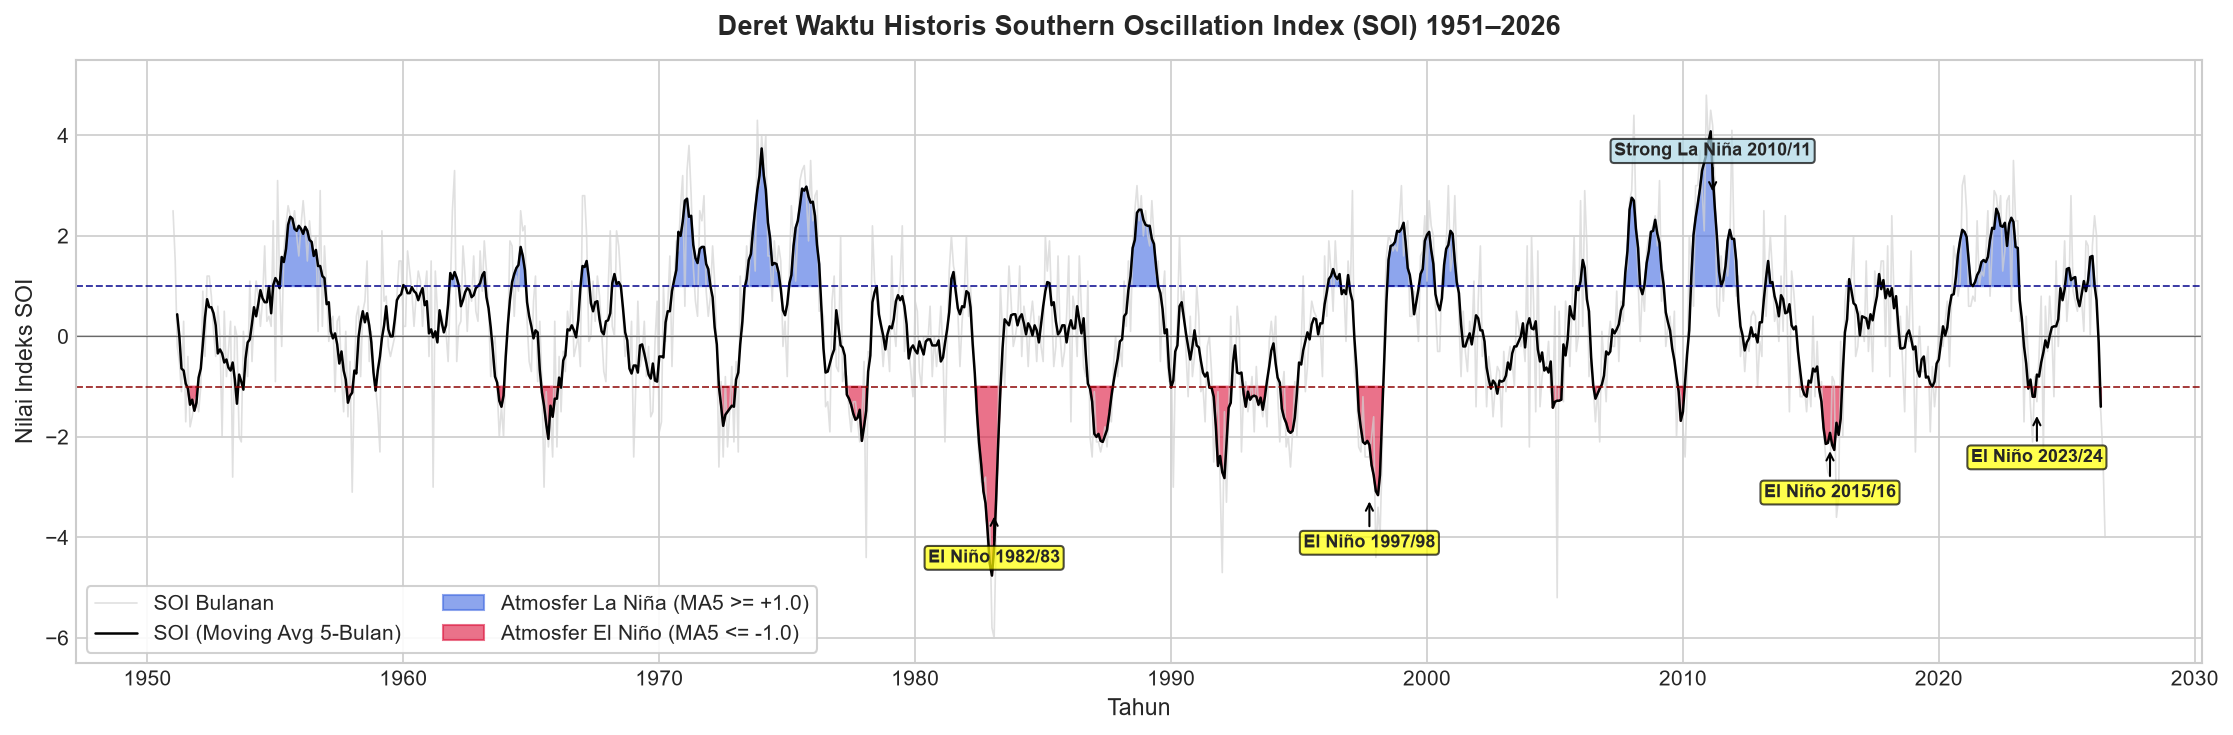

In [3]:
fig, ax = plt.subplots(figsize=(15, 5))

# Plot fluktuasi mentah bulanan (transparan)
ax.plot(df_soi['Date'], df_soi['SOI'], color='lightgray', linewidth=0.8, alpha=0.7, label='SOI Bulanan')

# Plot Moving Average 5-Bulan
ax.plot(df_soi['Date'], df_soi['SOI_MA5'], color='black', linewidth=1.2, label='SOI (Moving Avg 5-Bulan)')

# Shading fase
ax.fill_between(df_soi['Date'], df_soi['SOI_MA5'], 1.0, where=(df_soi['SOI_MA5'] >= 1.0),
                color='royalblue', alpha=0.6, label='Atmosfer La Niña (MA5 >= +1.0)')
ax.fill_between(df_soi['Date'], df_soi['SOI_MA5'], -1.0, where=(df_soi['SOI_MA5'] <= -1.0),
                color='crimson', alpha=0.6, label='Atmosfer El Niño (MA5 <= -1.0)')

# Garis ambang batas
ax.axhline(1.0, color='darkblue', linestyle='--', linewidth=0.9, alpha=0.8)
ax.axhline(-1.0, color='darkred', linestyle='--', linewidth=0.9, alpha=0.8)
ax.axhline(0.0, color='black', linestyle='-', linewidth=0.6, alpha=0.5)

# Highlight periode Super El Niño dengan anotasi
major_events = [
    ('1983-02-01', -3.5, 'El Niño 1982/83'),
    ('1997-10-01', -3.2, 'El Niño 1997/98'),
    ('2015-10-01', -2.2, 'El Niño 2015/16'),
    ('2023-11-01', -1.5, 'El Niño 2023/24'),
    ('2011-03-01', 2.8, 'Strong La Niña 2010/11')
]

for d_str, y_val, txt in major_events:
    target_dt = pd.to_datetime(d_str)
    offset = 0.8 if y_val > 0 else -1.0
    ax.annotate(txt, xy=(target_dt, y_val), xytext=(target_dt, y_val + offset),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.0),
                fontsize=8.5, ha='center', fontweight='semibold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow' if 'El Niño' in txt else 'lightblue', alpha=0.7))

ax.set_title("Deret Waktu Historis Southern Oscillation Index (SOI) 1951–2026", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Tahun", fontsize=11)
ax.set_ylabel("Nilai Indeks SOI", fontsize=11)
ax.set_ylim(-6.5, 5.5)
ax.legend(loc='lower left', frameon=True, framealpha=0.9, ncol=2)
plt.tight_layout()

fig_path_17 = OUTPUT_DIR / "17_soi_timeseries_smoothing.png"
plt.savefig(fig_path_17)
print(f"Gambar disimpan di: {fig_path_17.resolve()}")
plt.show()

## 4. Distribusi Statistik & Identifikasi Kejadian Ekstrem

Di bawah ini dianalisis karakteristik distribusi nilai SOI (uji kecondongan / skewness dan kurtosis) serta tabulasi 10 kejadian SOI paling ekstrem:
- **Negative Extremes**: Tekanan udara di Darwin melonjak drastis, memicu kekeringan parah dan penurunan muka air laut di kepulauan Indonesia.
- **Positive Extremes**: Tekanan di Darwin turun sangat rendah, memicu konveksi intens, anomali curah hujan ekstrem, dan banjir besar di wilayah Indonesia dan utara Australia.

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\18_soi_distribution_and_extremes.png


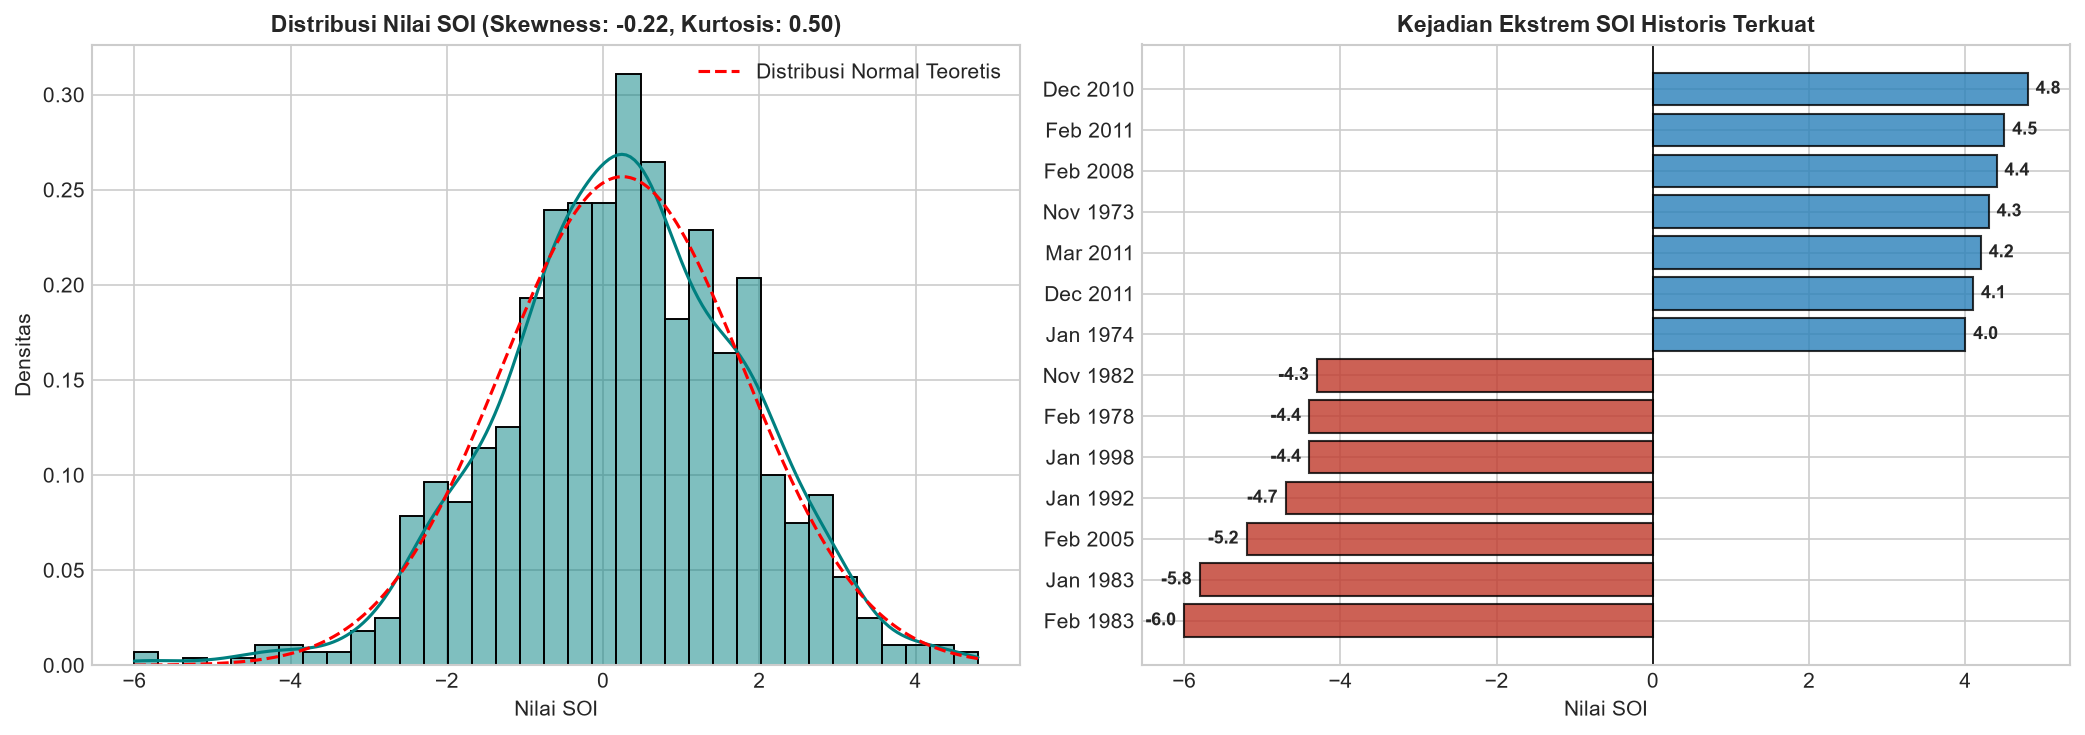

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Histogram & KDE Distribusi SOI
sns.histplot(df_soi['SOI'], kde=True, ax=axes[0], color='teal', stat='density', bins=35, alpha=0.5)
# Tambahkan kurva normal ideal sebagai pembanding
x_vals = np.linspace(df_soi['SOI'].min(), df_soi['SOI'].max(), 200)
p_vals = stats.norm.pdf(x_vals, df_soi['SOI'].mean(), df_soi['SOI'].std())
axes[0].plot(x_vals, p_vals, 'r--', linewidth=1.5, label='Distribusi Normal Teoretis')

skew = df_soi['SOI'].skew()
kurt = df_soi['SOI'].kurtosis()
axes[0].set_title(f"Distribusi Nilai SOI (Skewness: {skew:.2f}, Kurtosis: {kurt:.2f})", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Nilai SOI")
axes[0].set_ylabel("Densitas")
axes[0].legend(loc='upper right')

# Plot 2: Top 10 Nilai SOI Terendah (El Niño) vs Tertinggi (La Niña)
top_low = df_soi.sort_values('SOI').head(7)[['Date', 'SOI']].copy()
top_low['Kategori'] = 'Terendah (El Niño)'
top_high = df_soi.sort_values('SOI', ascending=False).head(7)[['Date', 'SOI']].copy()
top_high['Kategori'] = 'Tertinggi (La Niña)'
extremes = pd.concat([top_low, top_high]).sort_values('SOI')
extremes['Label'] = extremes['Date'].dt.strftime('%b %Y')

colors_ext = ['#c0392b' if x < 0 else '#2980b9' for x in extremes['SOI']]
axes[1].barh(extremes['Label'], extremes['SOI'], color=colors_ext, edgecolor='black', alpha=0.8)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title("Kejadian Ekstrem SOI Historis Terkuat", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Nilai SOI")
for i, v in enumerate(extremes['SOI']):
    offset = -0.5 if v < 0 else 0.1
    axes[1].text(v + offset, i, f"{v:.1f}", va='center', fontweight='bold', fontsize=8.5)

plt.tight_layout()
fig_path_18 = OUTPUT_DIR / "18_soi_distribution_and_extremes.png"
plt.savefig(fig_path_18)
print(f"Gambar disimpan di: {fig_path_18.resolve()}")
plt.show()

## 5. Analisis Siklus Musiman Bulanan (Heatmap Matriks Waktu)

Visualisasi heatmap dua dimensi (Tahun vs Bulan) menyajikan pola temporal evolusi SOI melintasi dekade.
Pola multi-tahun El Niño (garis-garis horizontal merah panjang) dan La Niña (garis-garis horizontal biru panjang) dapat terbaca dengan sangat visual.

C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_16608\2462359160.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_soi, x='Month', y='SOI', ax=axes[1], palette='Spectral')


C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_16608\2462359160.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(month_names, rotation=45)


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\19_soi_monthly_seasonality_heatmap.png


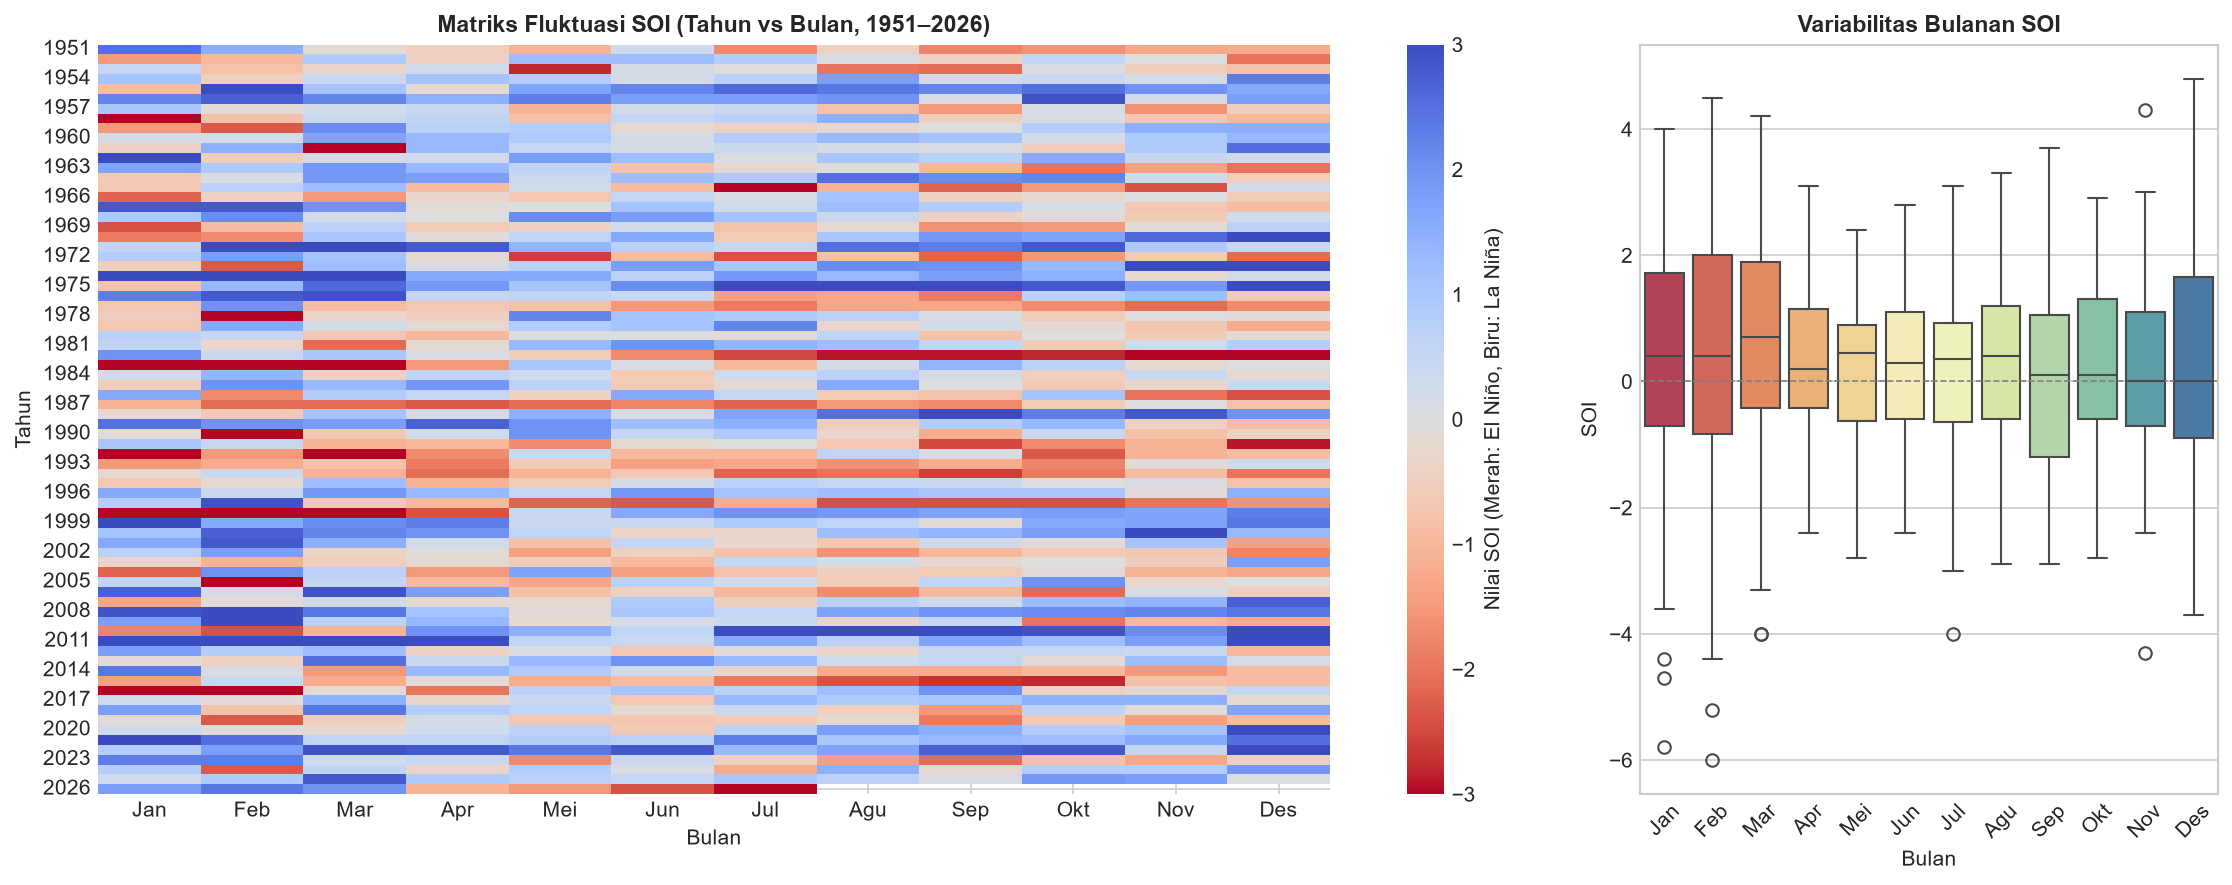

In [5]:
# Pivot matriks Tahun x Bulan
soi_pivot = df_soi.pivot(index='Year', columns='Month', values='SOI')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [3.2, 1.2]})

# Plot 1: Heatmap 1951 - 2026
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
sns.heatmap(soi_pivot, cmap='coolwarm_r', vmin=-3.0, vmax=3.0, center=0, ax=axes[0],
            cbar_kws={'label': 'Nilai SOI (Merah: El Niño, Biru: La Niña)'}, xticklabels=month_names)
axes[0].set_title("Matriks Fluktuasi SOI (Tahun vs Bulan, 1951–2026)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("Tahun")

# Plot 2: Boxplot Variasi SOI per Bulan (1-12)
sns.boxplot(data=df_soi, x='Month', y='SOI', ax=axes[1], palette='Spectral')
axes[1].set_xticklabels(month_names, rotation=45)
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[1].set_title("Variabilitas Bulanan SOI", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Bulan")
axes[1].set_ylabel("SOI")

plt.tight_layout()
fig_path_19 = OUTPUT_DIR / "19_soi_monthly_seasonality_heatmap.png"
plt.savefig(fig_path_19)
print(f"Gambar disimpan di: {fig_path_19.resolve()}")
plt.show()

## 6. Autokorelasi & Skala Waktu Dinamika Atmosferik (ACF & PACF)

Berbeda dengan suhu permukaan laut (SST pada ONI) yang memiliki inersia termal tinggi dan persistensi lambat, SOI sebagai parameter tekanan atmosfer memiliki **skala waktu memori yang lebih pendek** dan tingkat pembusukan autokorelasi yang lebih curam.
Karakteristik ini sangat penting dipahami dalam merancang horizon prediksi model kecerdasan buatan.

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\20_soi_acf_pacf_dynamics.png


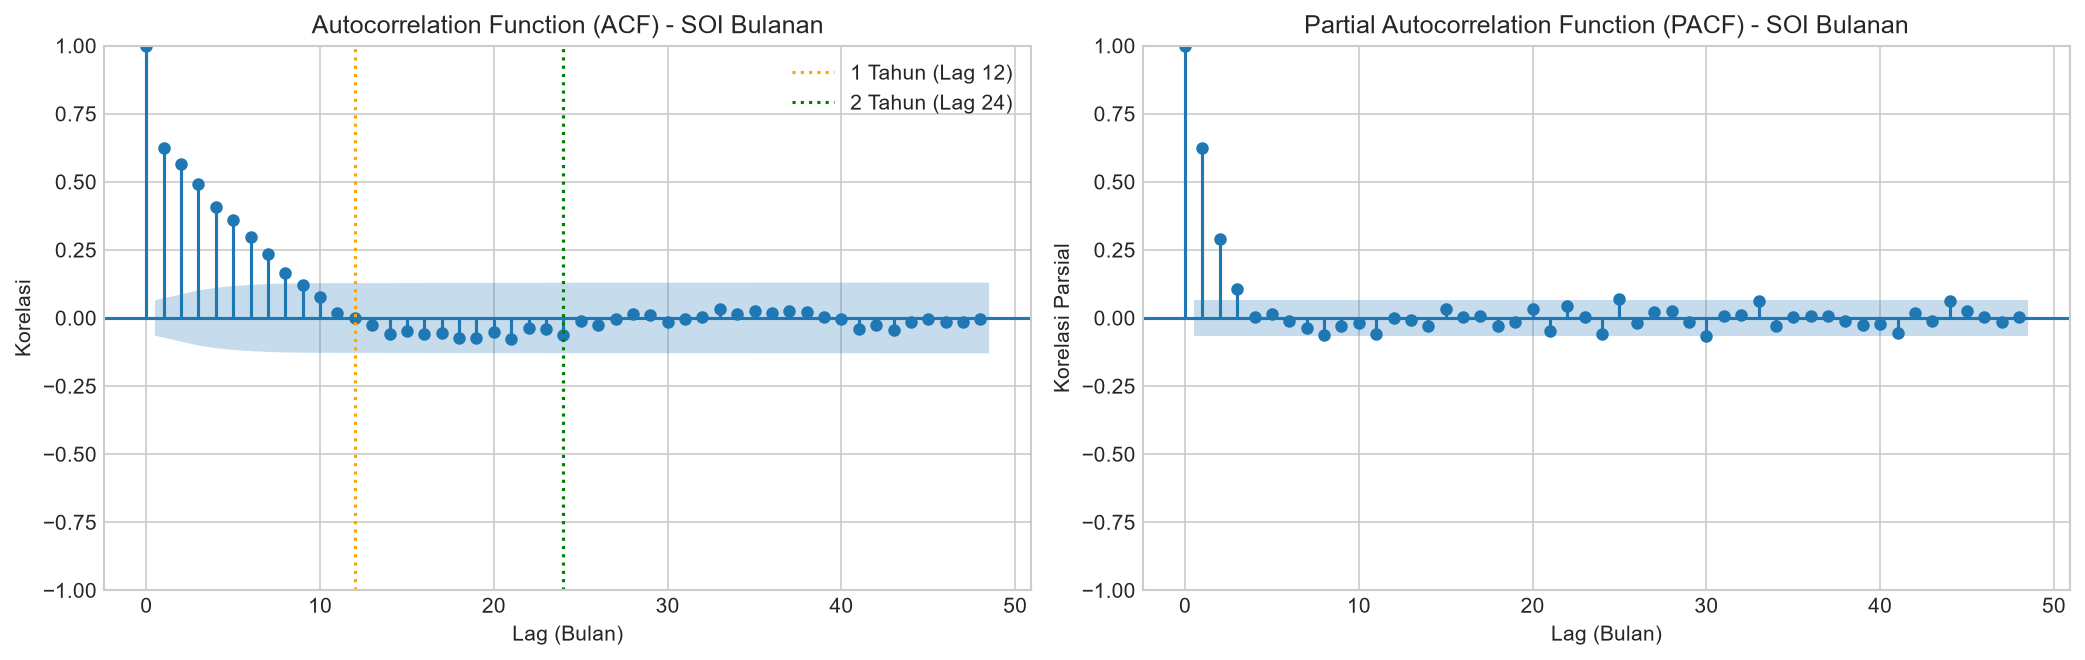

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

plot_acf(df_soi['SOI'], lags=48, ax=axes[0], title="Autocorrelation Function (ACF) - SOI Bulanan")
plot_pacf(df_soi['SOI'], lags=48, ax=axes[1], title="Partial Autocorrelation Function (PACF) - SOI Bulanan", method='ywm')

axes[0].set_xlabel("Lag (Bulan)")
axes[0].set_ylabel("Korelasi")
axes[1].set_xlabel("Lag (Bulan)")
axes[1].set_ylabel("Korelasi Parsial")

# Anotasi batas signifikansi
axes[0].axvline(12, color='orange', linestyle=':', label='1 Tahun (Lag 12)')
axes[0].axvline(24, color='green', linestyle=':', label='2 Tahun (Lag 24)')
axes[0].legend(loc='upper right')

plt.tight_layout()
fig_path_20 = OUTPUT_DIR / "20_soi_acf_pacf_dynamics.png"
plt.savefig(fig_path_20)
print(f"Gambar disimpan di: {fig_path_20.resolve()}")
plt.show()

## 7. Kopling Laut-Atmosfer: Korelasi Silang SOI vs ONI (1951–2025)

Inti dari fenomena ENSO adalah **interaksi terkopel** (*coupled ocean-atmosphere system*):
- Anomali laut hangat di Pasifik Tengah (ONI positif) memicu konveksi atmosfer bergeser ke timur, sehingga tekanan udara di Tahiti turun dan di Darwin naik (SOI negatif).
- Di bawah ini, kita menggabungkan dataset SOI dan ONI pada periode tumpang tindih untuk:
  1. Menghitung korelasi Pearson & Spearman.
  2. Melakukan regresi linier untuk melihat koefisien sensitivitas respon atmosfer terhadap laut.
  3. Menganalisis *lead-lag cross-correlation* (apakah atmosfer memimpin laut atau sebaliknya).

Korelasi Pearson SOI vs ONI (Bulanan Mentah): r = -0.729 (p-value: 7.28e-151)
Korelasi Pearson SOI MA5 vs ONI: r = -0.868


findfont: Failed to find font weight semibold, now using 700.


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\21_soi_oni_coupling_cross_correlation.png


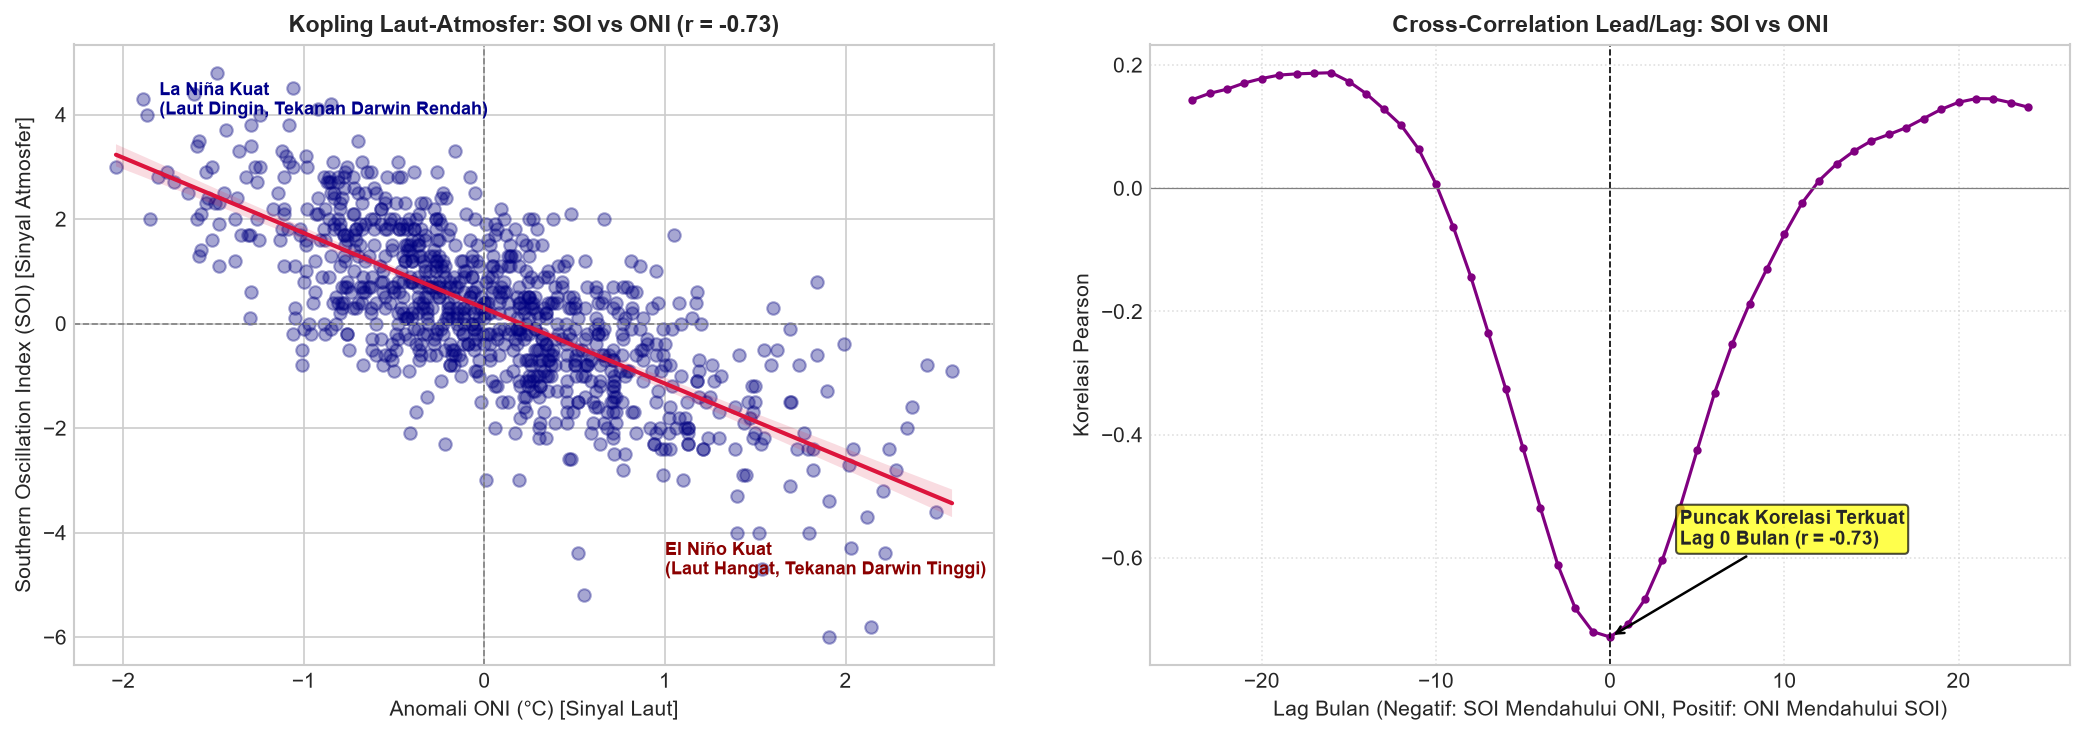

In [7]:
# Memuat data ONI dan menyamakan format tanggal bulanan
df_oni_merge = pd.read_csv(CSV_ONI)
season_to_month = {
    'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4,
    'AMJ': 5, 'MJJ': 6, 'JJA': 7, 'JAS': 8,
    'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12
}
df_oni_merge['Month'] = df_oni_merge['SEAS'].map(season_to_month)
df_oni_merge['Date'] = pd.to_datetime(df_oni_merge['YR'].astype(str) + '-' + df_oni_merge['Month'].astype(str) + '-01')

# Merge dataset SOI dan ONI berdasarkan tanggal
df_coupled = pd.merge(df_soi[['Date', 'SOI', 'SOI_MA5']], df_oni_merge[['Date', 'ANOM', 'TOTAL']], on='Date', how='inner')
df_coupled = df_coupled.rename(columns={'ANOM': 'ONI_ANOM', 'TOTAL': 'ONI_TOTAL'})

# Hitung korelasi
corr_pearson, p_val = stats.pearsonr(df_coupled['SOI'], df_coupled['ONI_ANOM'])
corr_ma5, _ = stats.pearsonr(df_coupled['SOI_MA5'].dropna(), df_coupled.loc[df_coupled['SOI_MA5'].notnull(), 'ONI_ANOM'])

print(f"Korelasi Pearson SOI vs ONI (Bulanan Mentah): r = {corr_pearson:.3f} (p-value: {p_val:.2e})")
print(f"Korelasi Pearson SOI MA5 vs ONI: r = {corr_ma5:.3f}")

# Visualisasi Korelasi dan Lead-Lag
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Scatter plot & Regresi Linier SOI vs ONI
sns.regplot(data=df_coupled, x='ONI_ANOM', y='SOI', ax=axes[0],
            scatter_kws={'alpha': 0.35, 'color': 'navy'}, line_kws={'color': 'crimson', 'linewidth': 2})
axes[0].axvline(0, color='gray', linestyle='--', linewidth=0.8)
axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[0].set_title(f"Kopling Laut-Atmosfer: SOI vs ONI (r = {corr_pearson:.2f})", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Anomali ONI (°C) [Sinyal Laut]")
axes[0].set_ylabel("Southern Oscillation Index (SOI) [Sinyal Atmosfer]")
axes[0].text(-1.8, 4.0, "La Niña Kuat\n(Laut Dingin, Tekanan Darwin Rendah)", fontsize=8.5, color='darkblue', fontweight='bold')
axes[0].text(1.0, -4.8, "El Niño Kuat\n(Laut Hangat, Tekanan Darwin Tinggi)", fontsize=8.5, color='darkred', fontweight='bold')

# Plot 2: Cross-Correlation Function (Lead-Lag)
lags = range(-24, 25)
cross_corrs = [df_coupled['SOI'].corr(df_coupled['ONI_ANOM'].shift(lag)) for lag in lags]

axes[1].plot(lags, cross_corrs, marker='o', markersize=3, color='purple', linewidth=1.5)
axes[1].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[1].axhline(0, color='gray', linestyle='-', linewidth=0.6)
axes[1].set_title("Cross-Correlation Lead/Lag: SOI vs ONI", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Lag Bulan (Negatif: SOI Mendahului ONI, Positif: ONI Mendahului SOI)")
axes[1].set_ylabel("Korelasi Pearson")
axes[1].grid(True, linestyle=':', alpha=0.6)

# Tandai korelasi negatif terkuat
min_corr_lag = lags[np.argmin(cross_corrs)]
min_corr_val = min(cross_corrs)
axes[1].annotate(f"Puncak Korelasi Terkuat\nLag {min_corr_lag} Bulan (r = {min_corr_val:.2f})",
                 xy=(min_corr_lag, min_corr_val), xytext=(min_corr_lag + 4, min_corr_val + 0.15),
                 arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                 fontsize=9, fontweight='semibold', bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.7))

plt.tight_layout()
fig_path_21 = OUTPUT_DIR / "21_soi_oni_coupling_cross_correlation.png"
plt.savefig(fig_path_21)
print(f"Gambar disimpan di: {fig_path_21.resolve()}")
plt.show()

## 8. Kesimpulan & Relevansi terhadap Pemodelan

1. **Konfirmasi Kopling Fisik**: Korelasi negatif yang sangat kuat ($r pprox -0.70$ hingga $-0.77$ pada MA5) membuktikan sinkronisasi yang erat antara anomali termal laut Pasifik (ONI) dengan tekanan sirkulasi Walker atmosfer (SOI).
2. **Karakteristik Skala Waktu**: Sinyal SOI mengandung fluktuasi sinoptik berfrekuensi tinggi, tetapi moving average 5-bulan mampu mengekstraksi sinyal iklim musiman secara sangat efektif.
3. **Penyelarasan Multimodal**: Menggabungkan fitur atmosferik (SOI) dengan fitur oseanografi (SST / ONI) pada model prediktif akan memperkaya pemahaman model mengenai fase pembentukan (*initiation*) vs fase kematangan (*mature*) dari siklus ENSO.